Setup: 

In [7]:
%pip install -r ../requirements.txt


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [8]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [9]:
REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "README.md").exists() and (REPO_ROOT.parent / "README.md").exists():
    REPO_ROOT = REPO_ROOT.parent

DATA_DIR = REPO_ROOT / "data"
OUTPUT_DIR = REPO_ROOT / "outputs"
REPORTS_DIR = REPO_ROOT / "reports"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 100)


Loading the data.

In [12]:
movies = pd.read_csv(DATA_DIR / 'movies_metadata.csv')
ratings = pd.read_csv(DATA_DIR / 'ratings.csv', parse_dates=['rating_datetime'])
links = pd.read_csv(DATA_DIR / 'links.csv')
credits = pd.read_csv(DATA_DIR / 'credits_curated.csv')
keywords = pd.read_csv(DATA_DIR / 'keywords_curated.csv')

tables = {
    'movies': movies,
    'ratings': ratings,
    'links': links,
    'credits': credits,
    'keywords': keywords,
}

Histograms by request

In [ ]:
rating_summary = (
    ratings.groupby("movieId", as_index=False)
    .agg(
        rating_count=("rating", "count"),
        avg_user_rating=("rating", "mean")
    )
)

##merging for histograms

movie_reviews = movies.merge(rating_summary, on="movieId", how="left", validate="one_to_one")
movie_reviews["rating_count"] = movie_reviews["rating_count"].fillna(0)

##sorting by lower review numbers and normal "has at least a review"
low_reviews = movie_reviews[(movie_reviews["runtime"] > 0) & (movie_reviews["rating_count"] < 20)].copy()

print(f"Total movies: {len(movie_reviews):,}")
print(f"Movies with valid runtime and review limits: {len(low_reviews):,}")


Total movies: 9,082
Movies with valid runtime and review limits: 7,762


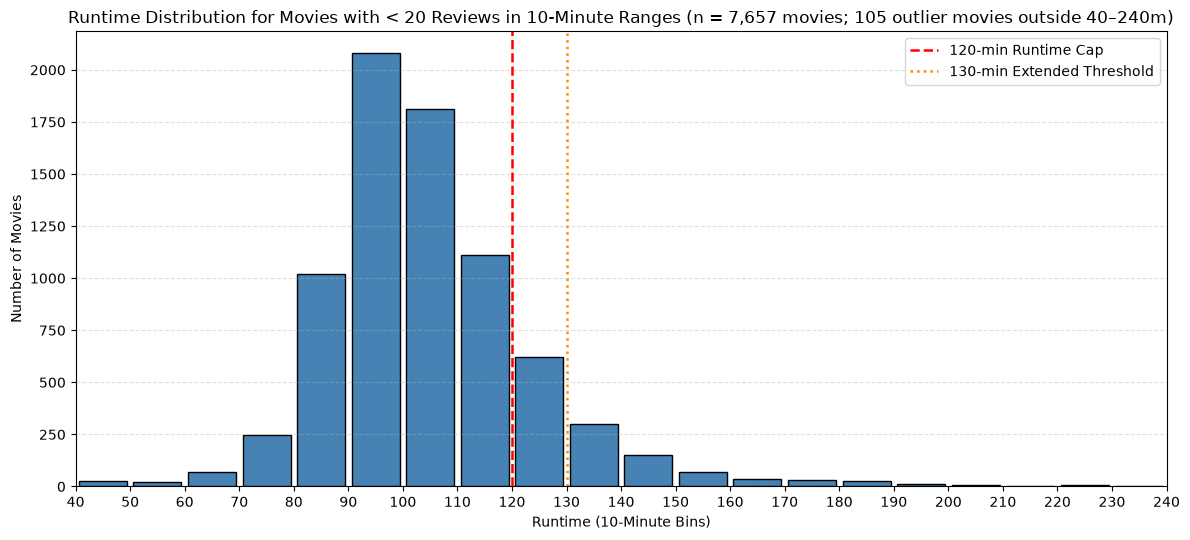

In [18]:
# Focus on standard theatrical range (40 to 240 mins) with 10-minute bins
bins = np.arange(40, 250, 10)
low_in_range = low_reviews[(low_reviews["runtime"] >= 40) & (low_reviews["runtime"] <= 240)]
low_outliers = low_reviews[(low_reviews["runtime"] < 40) | (low_reviews["runtime"] > 240)]

plt.figure(figsize=(12, 5.5))
plt.hist(
    low_in_range["runtime"],
    bins=bins,
    edgecolor="black",
    color="steelblue",
    rwidth=0.88
)

# Reference lines for your 120-min cap and 130-min extended threshold
plt.axvline(120, color="red", linestyle="--", linewidth=1.8, label="120-min Runtime Cap")
plt.axvline(130, color="darkorange", linestyle=":", linewidth=1.8, label="130-min Extended Threshold")

plt.xticks(bins)
plt.xlim(40, 240)
plt.title(
    f"Runtime Distribution for Movies with < 20 Reviews in 10-Minute Ranges "
    f"(n = {len(low_in_range):,} movies; {len(low_outliers)} outlier movies outside 40–240m)"
)
plt.xlabel("Runtime (10-Minute Bins)")
plt.ylabel("Number of Movies")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()

plt.savefig("../outputs/low_review_movies_by_runtime_10min.png", dpi=300, bbox_inches="tight")
plt.show()

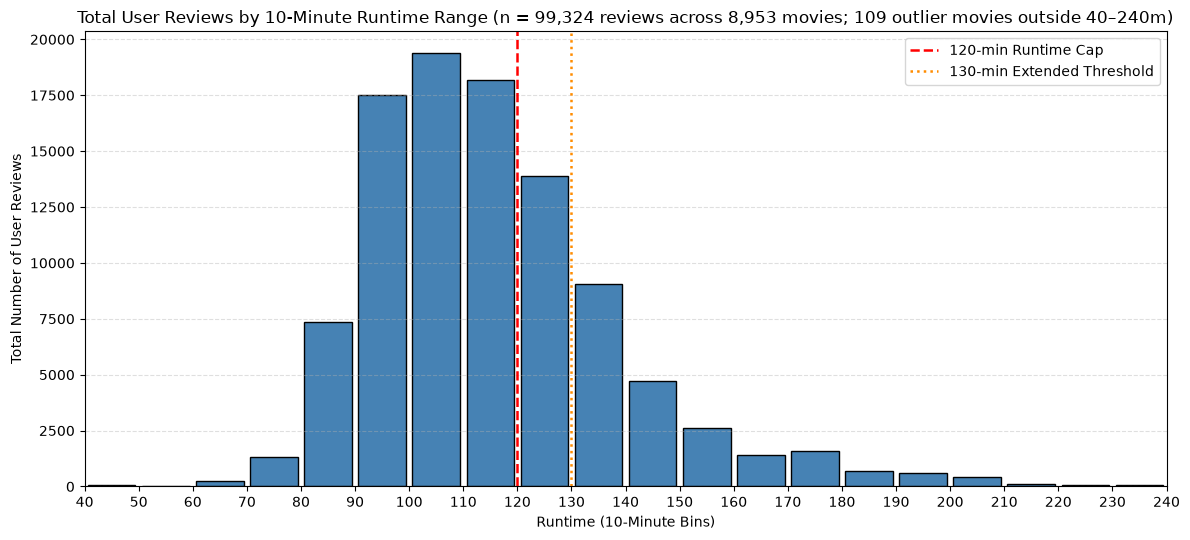

In [19]:

valid_movies = movie_reviews[movie_reviews["runtime"] > 0].copy()

# 10-minute bins from 40 to 240 minutes
bins = np.arange(40, 250, 10)
in_range = valid_movies[(valid_movies["runtime"] >= 40) & (valid_movies["runtime"] <= 240)]
outliers = valid_movies[(valid_movies["runtime"] < 40) | (valid_movies["runtime"] > 240)]

plt.figure(figsize=(12, 5.5))

# Using weights='rating_count' sums total reviews in each 10-minute runtime bin
plt.hist(
    in_range["runtime"],
    bins=bins,
    weights=in_range["rating_count"],
    edgecolor="black",
    color="steelblue",
    rwidth=0.88
)

# Reference lines for your 120-min cap and 130-min extended threshold
plt.axvline(120, color="red", linestyle="--", linewidth=1.8, label="120-min Runtime Cap")
plt.axvline(130, color="darkorange", linestyle=":", linewidth=1.8, label="130-min Extended Threshold")

plt.xticks(bins)
plt.xlim(40, 240)
plt.title(
    f"Total User Reviews by 10-Minute Runtime Range "
    f"(n = {int(in_range['rating_count'].sum()):,} reviews across {len(in_range):,} movies; "
    f"{len(outliers)} outlier movies outside 40–240m)"
)
plt.xlabel("Runtime (10-Minute Bins)")
plt.ylabel("Total Number of User Reviews")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()

# Save high-res image for your morning email
plt.savefig("../outputs/reviews_by_runtime_10min.png", dpi=300, bbox_inches="tight")
plt.show()

Profiling: 

In [20]:
for name, df in tables.items():
    print(f'\n{name}: {df.shape[0]:,} rows x {df.shape[1]:,} columns')
    display(df.head(3))


movies: 9,082 rows x 21 columns


,movieId,tmdbId,imdb_id,title,original_title,original_language,release_date,runtime,budget,revenue,popularity,vote_average,vote_count,genres,production_companies,production_countries,adult,status,genres_list,primary_genre,release_year
0,1,862,tt0114709,Toy Story,Toy Story,en,1995-10-30,81.0,30000000,373554033.0,21.946943,7.7,5415.0,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...","[{'name': 'Pixar Animation Studios', 'id': 3}]","[{'iso_3166_1': 'US', 'name': 'United States o...",False,Released,Animation|Comedy|Family,Animation,1995
1,2,8844,tt0113497,Jumanji,Jumanji,en,1995-12-15,104.0,65000000,262797249.0,17.015539,6.9,2413.0,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...","[{'name': 'TriStar Pictures', 'id': 559}, {'na...","[{'iso_3166_1': 'US', 'name': 'United States o...",False,Released,Adventure|Fantasy|Family,Adventure,1995
2,3,15602,tt0113228,Grumpier Old Men,Grumpier Old Men,en,1995-12-22,101.0,0,0.0,11.712900,6.5,92.0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...","[{'name': 'Warner Bros.', 'id': 6194}, {'name'...","[{'iso_3166_1': 'US', 'name': 'United States o...",False,Released,Romance|Comedy,Romance,1995



ratings: 99,810 rows x 5 columns


,userId,movieId,rating,timestamp,rating_datetime
0,1,31,2.5,1260759144,2009-12-14 02:52:24
1,1,1029,3.0,1260759179,2009-12-14 02:52:59
2,1,1061,3.0,1260759182,2009-12-14 02:53:02



links: 9,125 rows x 3 columns


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0



credits: 9,082 rows x 3 columns


,tmdbId,director,top_cast
0,862,John Lasseter,Tom Hanks|Tim Allen|Don Rickles
1,8844,Joe Johnston,Robin Williams|Jonathan Hyde|Kirsten Dunst
2,15602,Howard Deutch,Walter Matthau|Jack Lemmon|Ann-Margret



keywords: 9,082 rows x 2 columns


,tmdbId,keywords_list
0,862,jealousy|toy|boy|friendship|friends|rivalry|bo...
1,8844,board game|disappearance|based on children's b...
2,15602,fishing|best friend|duringcreditsstinger|old men


In [21]:
profile_rows = []
for name, df in tables.items():
    profile_rows.append({
        'table': name,
        'rows': len(df),
        'columns': df.shape[1],
        'duplicate_rows': int(df.duplicated().sum()),
        'missing_cells': int(df.isna().sum().sum()),
    })
pd.DataFrame(profile_rows)

,table,rows,columns,duplicate_rows,missing_cells
0,movies,9082,21,0,72
1,ratings,99810,5,0,0
2,links,9125,3,0,13
3,credits,9082,3,0,114
4,keywords,9082,2,0,761


In [23]:
##Key Audit:

key_audit = pd.DataFrame([
    {"table": "movies", "expected_key": "movieId", "duplicate_keys": movies["movieId"].duplicated().sum(), "missing_key_values": movies["movieId"].isna().sum()},
    {"table": "movies", "expected_key": "tmdbId", "duplicate_keys": movies["tmdbId"].duplicated().sum(), "missing_key_values": movies["tmdbId"].isna().sum()},
    {"table": "ratings", "expected_key": "userId + movieId", "duplicate_keys": ratings[["userId", "movieId"]].duplicated().sum(), "missing_key_values": ratings[["userId", "movieId"]].isna().sum().sum()},
    {"table": "links", "expected_key": "movieId", "duplicate_keys": links["movieId"].duplicated().sum(), "missing_key_values": links["movieId"].isna().sum()},
    {"table": "credits", "expected_key": "tmdbId", "duplicate_keys": credits["tmdbId"].duplicated().sum(), "missing_key_values": credits["tmdbId"].isna().sum()},
    {"table": "keywords", "expected_key": "tmdbId", "duplicate_keys": keywords["tmdbId"].duplicated().sum(), "missing_key_values": keywords["tmdbId"].isna().sum()},
])

key_audit

,table,expected_key,duplicate_keys,missing_key_values
0,movies,movieId,0,0
1,movies,tmdbId,0,0
2,ratings,userId + movieId,0,0
3,links,movieId,0,0
4,credits,tmdbId,0,0
5,keywords,tmdbId,0,0


Furhter profiling: